## 1. Import libraries and set reproducibility

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

## 2. Load and explore the data

In [2]:
df = pd.read_csv("adult.csv")

In [3]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


In [5]:
df.shape

(32561, 15)

##  Clean missing-value markers and define the target

In [6]:
# Convert '?' markers to proper missing values for the feature columns.
df = df.replace(r"^\s*\?\s*$", np.nan, regex=True)

# Normalise target labels. Some Adult Census versions include a trailing period.
df["income"] = df["income"].astype(str).str.strip().str.rstrip(".")

# Keep only the two expected target labels, then map them to 0 and 1.
df = df[df["income"].isin(["<=50K", ">50K"])].copy()
y = df["income"].map({"<=50K": 0, ">50K": 1}).astype("int32")
X = df.drop(columns=["income"])

print("Missing feature values after replacing '?':")
display(X.isna().sum().sort_values(ascending=False).head(10))
print("Target distribution:")
display(y.value_counts().rename(index={0: "<=50K (0)", 1: ">50K (1)"}))

Missing feature values after replacing '?':


occupation        1843
workclass         1836
native.country     583
education            0
fnlwgt               0
age                  0
marital.status       0
education.num        0
race                 0
relationship         0
dtype: int64

Target distribution:


income
<=50K (0)    24720
>50K (1)      7841
Name: count, dtype: int64

## Split into train, validation, and test sets

In [7]:
# 70% training, 15% validation, 15% test; stratify preserves the class balance.
X_train_df, X_temp_df, y_train_series, y_temp_series = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

X_val_df, X_test_df, y_val_series, y_test_series = train_test_split(
    X_temp_df, y_temp_series,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp_series
)

print("Train:", X_train_df.shape, y_train_series.shape)
print("Validation:", X_val_df.shape, y_val_series.shape)
print("Test:", X_test_df.shape, y_test_series.shape)

Train: (22792, 14) (22792,)
Validation: (4884, 14) (4884,)
Test: (4885, 14) (4885,)


##  Impute, encode, and scale without data leakage

In [8]:
numeric_columns = X_train_df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_train_df.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Fit only on training features. Validation and test are transformed using the same fitted pipeline.
X_train = preprocessor.fit_transform(X_train_df).astype("float32")
X_val = preprocessor.transform(X_val_df).astype("float32")
X_test = preprocessor.transform(X_test_df).astype("float32")

y_train = y_train_series.to_numpy(dtype="float32").ravel()
y_val = y_val_series.to_numpy(dtype="float32").ravel()
y_test = y_test_series.to_numpy(dtype="float32").ravel()

input_dim = X_train.shape[1]
print("Processed feature count:", input_dim)
print("Processed shapes:", X_train.shape, X_val.shape, X_test.shape)

Processed feature count: 104
Processed shapes: (22792, 104) (4884, 104) (4885, 104)


##  Define the three required network architectures

In [18]:
def compile_binary_model(model, optimizer="adam"):
    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


def build_baseline(input_dim):
    # 1–2 hidden layers, ReLU, Adam
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ])
    return compile_binary_model(model, optimizer=tf.keras.optimizers.Adam(learning_rate=0.001))


def build_deep(input_dim):
    # More hidden layers and units to test whether extra capacity helps or overfits.
    model = Sequential([
        Input(shape=(input_dim,)),
        
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(16, activation="relu"),
        Dense(1, activation="sigmoid")
    ])
    return compile_binary_model(model, optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005))


def build_regularised(input_dim):
    # Dropout + batch normalisation; early stopping is applied during training.
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(128, activation="relu"),
        BatchNormalization(),
        Dropout(0.30),
        Dense(64, activation="relu"),
        BatchNormalization(),
        Dropout(0.30),
        Dense(32, activation="relu"),
        Dropout(0.20),
        Dense(1, activation="sigmoid")
    ])
    return compile_binary_model(model, optimizer=tf.keras.optimizers.Adam(learning_rate=0.001))


def make_early_stopping():
    # Create a fresh callback for each fit call.
    return EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

##  Train each architecture once and save its history

In [19]:
model_builders = {
    "Baseline MLP": build_baseline,
    "Deeper DNN": build_deep,
    "Regularised DNN": build_regularised
}

models = {}
histories = {}

for name, builder in model_builders.items():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = builder(input_dim)
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        callbacks=[make_early_stopping()],
        verbose=1
    )

    models[name] = model
    histories[name] = history

print("Trained models:", list(models.keys()))

Epoch 1/50
713/713 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8451 - loss: 0.3343 - val_accuracy: 0.8522 - val_loss: 0.3192
Epoch 2/50
713/713 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8590 - loss: 0.3058 - val_accuracy: 0.8509 - val_loss: 0.3178
Epoch 3/50
713/713 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8607 - loss: 0.3010 - val_accuracy: 0.8509 - val_loss: 0.3175
Epoch 4/50
713/713 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8626 - loss: 0.2975 - val_accuracy: 0.8493 - val_loss: 0.3176
Epoch 5/50
713/713 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8643 - loss: 0.2945 - val_accuracy: 0.8491 - val_loss: 0.3182
Epoch 6/50
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8653 - loss: 0.2914 - val_accuracy: 0.8489 - val_loss: 0.3187
Epoch 1/50
713/713 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8297 - loss: 0.3576 - val_accuracy: 0.8514 - val_loss: 0.3208
Epoch 2/50
713/713 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8567 - loss: 0.3075 - val_accuracy: 0.

In [20]:
for name, history in histories.items():
    val_losses = history.history["val_loss"]

    print(name)
    print("Epochs trained:", len(val_losses))
    print("Best epoch:", val_losses.index(min(val_losses)) + 1)
    print("Best validation loss:", round(min(val_losses), 4))
    print("Final validation loss:", round(val_losses[-1], 4))
    print()

Baseline MLP
Epochs trained: 6
Best epoch: 3
Best validation loss: 0.3175
Final validation loss: 0.3187

Deeper DNN
Epochs trained: 7
Best epoch: 4
Best validation loss: 0.3183
Final validation loss: 0.3191

Regularised DNN
Epochs trained: 11
Best epoch: 8
Best validation loss: 0.3191
Final validation loss: 0.3228



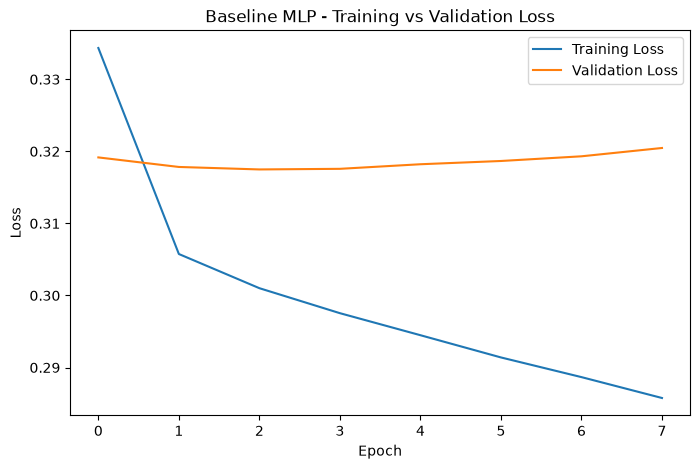

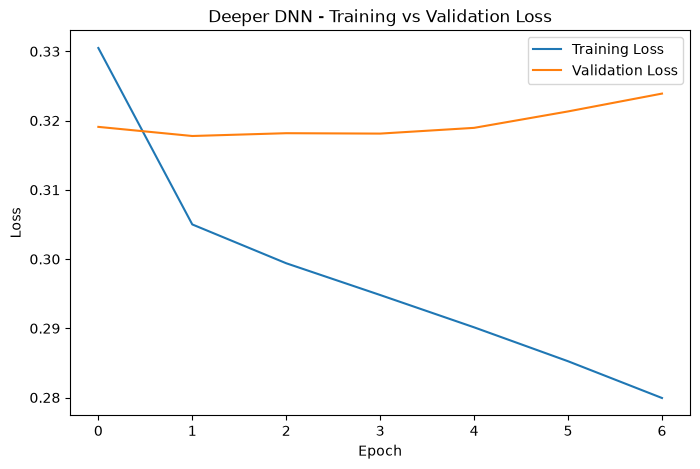

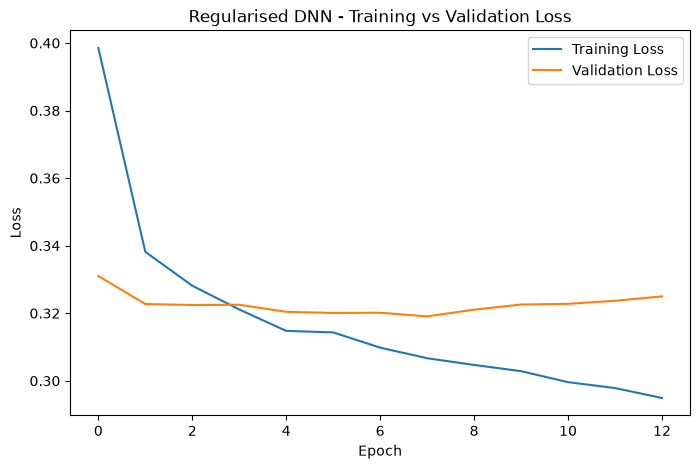

In [12]:
import matplotlib.pyplot as plt

for name, history in histories.items():
    plt.figure(figsize=(8, 5))

    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")

    plt.title(f"{name} - Training vs Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.savefig(
        f"{name.lower().replace(' ', '_')}_loss_curve.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.savefig("baseline_loss_curve.png", bbox_inches="tight")
    plt.show()

##  Plot training and validation loss/accuracy

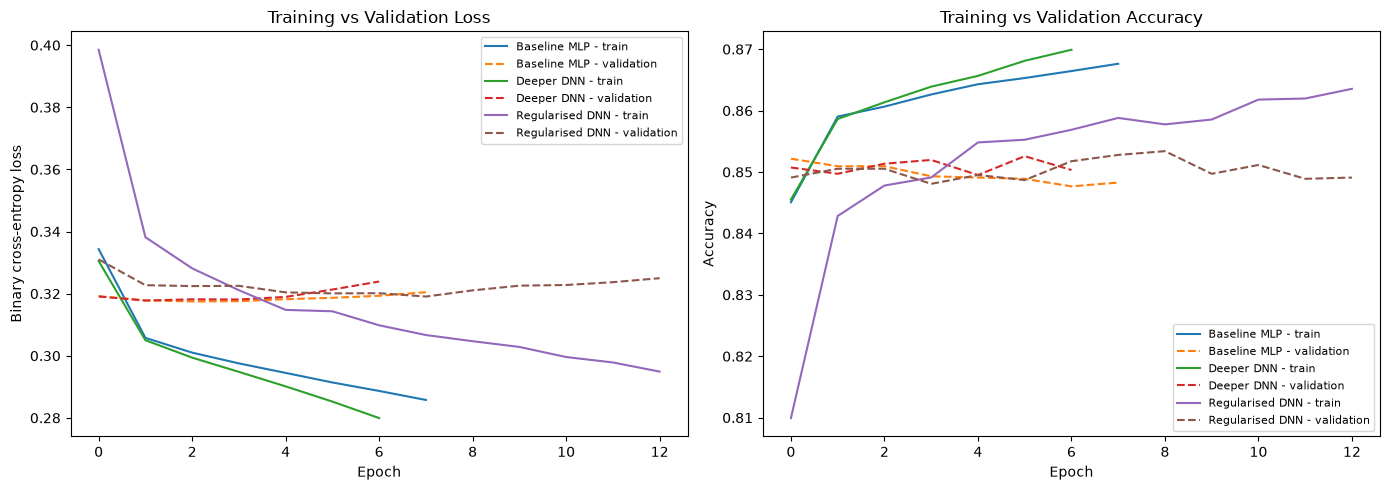

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in histories.items():
    axes[0].plot(history.history["loss"], label=f"{name} - train")
    axes[0].plot(history.history["val_loss"], linestyle="--", label=f"{name} - validation")
    axes[1].plot(history.history["accuracy"], label=f"{name} - train")
    axes[1].plot(history.history["val_accuracy"], linestyle="--", label=f"{name} - validation")

axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

##  Compare architectures on validation data

In [22]:
def calculate_metrics(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

architecture_results = []

for name, model in models.items():
    val_probabilities = model.predict(X_val, verbose=0).ravel()
    row = {"Model": name}
    row.update(calculate_metrics(y_val, val_probabilities))
    architecture_results.append(row)

architecture_results_df = pd.DataFrame(architecture_results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(architecture_results_df)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline MLP,0.850942,0.718324,0.626701,0.669391,0.906929
1,Regularised DNN,0.852785,0.732452,0.612245,0.666975,0.906651
2,Deeper DNN,0.849918,0.719090,0.618197,0.664838,0.906504


##  Validation confusion matrices for the three architectures

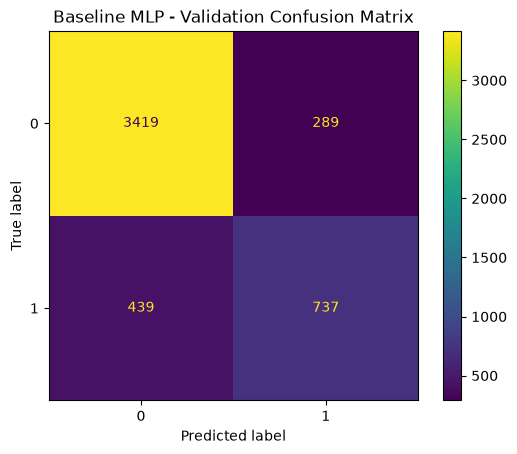

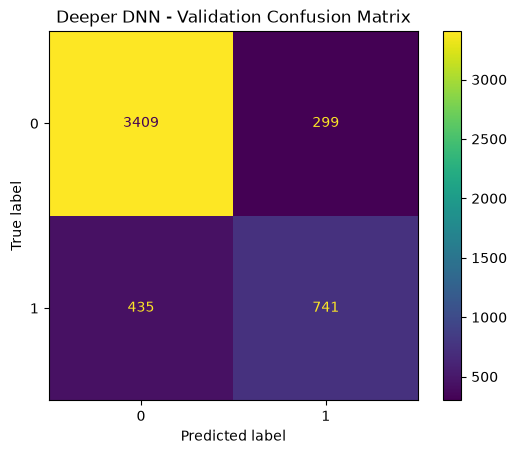

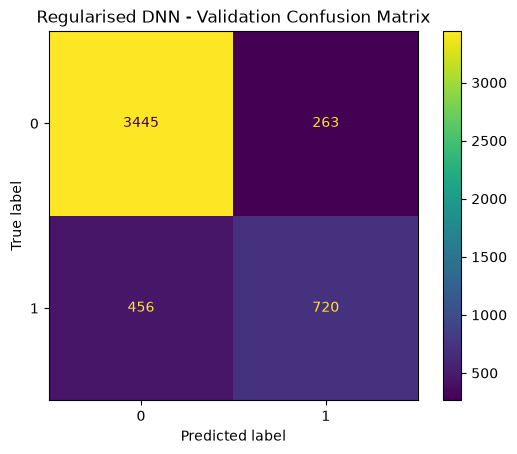

In [47]:
for name, model in models.items():
    val_probabilities = model.predict(X_val, verbose=0).ravel()
    val_predictions = (val_probabilities >= 0.5).astype(int)
    cm = confusion_matrix(y_val, val_predictions)

    ConfusionMatrixDisplay(confusion_matrix=cm).plot()
    plt.title(f"{name} - Validation Confusion Matrix")
    plt.show()

##  Optimiser and learning-rate experiments using the same MLP architecture

This experiment changes only the optimiser and learning rate while keeping the network architecture, training data, validation data, batch size, and epoch limit the same. It tests both Adam and SGD at all three learning rates: 0.1, 0.01, and 0.001. High learning rates can be unstable; poor results are useful experiment findings, not necessarily code errors.

In [23]:
def build_optimizer_model(input_dim, optimizer_name, learning_rate):
    # Same architecture for every experiment: only optimizer / learning rate changes.
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(1, activation="sigmoid")
    ])

    if optimizer_name == "Adam":
        optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
    elif optimizer_name == "SGD":
        optimizer = tf.keras.optimizers.SGD(learning_rate=learning_rate)
    else:
        raise ValueError(f"Unknown optimizer: {optimizer_name}")

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

learning_rates = [0.1, 0.01, 0.001]
optimizer_names = ["Adam", "SGD"]
optimizer_models = {}
optimizer_histories = {}
optimizer_results = []

for optimizer_name in optimizer_names:
    for learning_rate in learning_rates:
        run_name = f"{optimizer_name} LR={learning_rate}"
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)

        model = build_optimizer_model(input_dim, optimizer_name, learning_rate)
        history = model.fit(
            X_train, y_train,
            validation_data=(X_val, y_val),
            epochs=30,
            batch_size=32,
            callbacks=[make_early_stopping()],
            verbose=0
        )

        val_probabilities = model.predict(X_val, verbose=0).ravel()
        row = {"Experiment": run_name,
               "Optimizer": optimizer_name,
               "Learning Rate": learning_rate,
               "Epochs Trained": len(history.history["loss"])}
        row.update(calculate_metrics(y_val, val_probabilities))
        row["Best Validation Loss"] = float(np.min(history.history["val_loss"]))
        optimizer_results.append(row)
        optimizer_models[run_name] = model
        optimizer_histories[run_name] = history

optimizer_results_df = pd.DataFrame(optimizer_results).sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True)

display(optimizer_results_df)

,Experiment,Optimizer,Learning Rate,Epochs Trained,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Best Validation Loss
0,Adam LR=0.001,Adam,0.001,6,0.850942,0.718324,0.626701,0.669391,0.906929,0.317488
1,SGD LR=0.01,SGD,0.010,13,0.849509,0.720280,0.613095,0.662379,0.906458,0.318474
2,Adam LR=0.01,Adam,0.010,5,0.850942,0.732848,0.599490,0.659495,0.907192,0.317444
3,Adam LR=0.1,Adam,0.100,6,0.842547,0.691800,0.624150,0.656236,0.898237,0.340247
4,SGD LR=0.001,SGD,0.001,30,0.848075,0.723251,0.597789,0.654562,0.901247,0.328101
5,SGD LR=0.1,SGD,0.100,8,0.851556,0.745375,0.582483,0.653938,0.907131,0.318391


## 12. Combine validation results and choose a candidate model

In [49]:
# Combine architecture and optimiser experiments. Model selection uses validation F1 only.
all_candidate_models = {**models, **optimizer_models}

architecture_for_selection = architecture_results_df.rename(columns={"Model": "Experiment"}).copy()
optimizer_for_selection = optimizer_results_df.copy()

all_validation_results = pd.concat([
    architecture_for_selection[["Experiment", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]],
    optimizer_for_selection[["Experiment", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]]
], ignore_index=True).sort_values("F1 Score", ascending=False).reset_index(drop=True)

display(all_validation_results)

best_name = all_validation_results.iloc[0]["Experiment"]
best_model = all_candidate_models[best_name]
print("Selected using validation F1:", best_name)

,Experiment,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline MLP,0.850942,0.718324,0.626701,0.669391,0.906929
1,Adam LR=0.001,0.850942,0.718324,0.626701,0.669391,0.906929
2,Deeper DNN,0.849713,0.712500,0.630102,0.668773,0.906889
3,Regularised DNN,0.852785,0.732452,0.612245,0.666975,0.906651
4,SGD LR=0.01,0.849509,0.720280,0.613095,0.662379,0.906458
5,Adam LR=0.01,0.850942,0.732848,0.599490,0.659495,0.907192
6,Adam LR=0.1,0.842547,0.691800,0.624150,0.656236,0.898237
7,SGD LR=0.001,0.848075,0.723251,0.597789,0.654562,0.901247
8,SGD LR=0.1,0.851556,0.745375,0.582483,0.653938,0.907131


Selected using validation F1: Baseline MLP


## 13. MLflow experiment tracking (required if specified by your trainer)

In [ ]:

import mlflow

mlflow.set_experiment("Adult Census - Week 2 Neural Networks")

# Log the three architecture experiments.
for name, model in models.items():
    metrics_row = architecture_results_df.loc[architecture_results_df["Model"] == name].iloc[0]
    history = histories[name]

    with mlflow.start_run(run_name=name):
        mlflow.log_params({
            "experiment_type": "architecture",
            "architecture": name,
            "epochs_trained": len(history.history["loss"]),
            "batch_size": 32,
            "max_epochs": 50,
            "optimizer": "Adam",
            "learning_rate": 0.001,
            "threshold": 0.5
        })
        mlflow.log_metrics({
            "val_accuracy": float(metrics_row["Accuracy"]),
            "val_precision": float(metrics_row["Precision"]),
            "val_recall": float(metrics_row["Recall"]),
            "val_f1": float(metrics_row["F1 Score"]),
            "val_roc_auc": float(metrics_row["ROC-AUC"]),
            "final_train_loss": float(history.history["loss"][-1]),
            "final_val_loss": float(history.history["val_loss"][-1])
        })
        mlflow.tensorflow.log_model(model, name="model")

# Log optimiser / learning-rate experiments and their trained model artifacts.
for name, model in optimizer_models.items():
    metrics_row = optimizer_results_df.loc[optimizer_results_df["Experiment"] == name].iloc[0]

    with mlflow.start_run(run_name=name):
        mlflow.log_params({
            "experiment_type": "optimizer_learning_rate",
            "architecture": "64-32-1 MLP",
            "optimizer": metrics_row["Optimizer"],
            "learning_rate": float(metrics_row["Learning Rate"]),
            "epochs_trained": int(metrics_row["Epochs Trained"]),
            "batch_size": 32,
            "max_epochs": 30,
            "threshold": 0.5
        })
        mlflow.log_metrics({
            "val_accuracy": float(metrics_row["Accuracy"]),
            "val_precision": float(metrics_row["Precision"]),
            "val_recall": float(metrics_row["Recall"]),
            "val_f1": float(metrics_row["F1 Score"]),
            "val_roc_auc": float(metrics_row["ROC-AUC"]),
            "best_val_loss": float(metrics_row["Best Validation Loss"])
        })
        mlflow.tensorflow.log_model(model, name="model")

print("MLflow runs logged. Start the UI from a terminal with: mlflow ui")
print("Then open http://127.0.0.1:5000 in your browser.")

2026/10/19 13:30:58 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/10/19 13:31:08 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/19 13:31:08 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.
2026/10/19 13:31:16 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/19 13:31:17 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signa

MLflow runs logged. Start the UI from a terminal with: mlflow ui
Then open http://127.0.0.1:5000 in your browser.


In [89]:
import mlflow
import os

for file in os.listdir("."):
    if file.endswith("_loss_curve.png"):
        print(file)

baseline_loss_curve.png
baseline_mlp_loss_curve.png
deeper_dnn_loss_curve.png
regularised_dnn_loss_curve.png


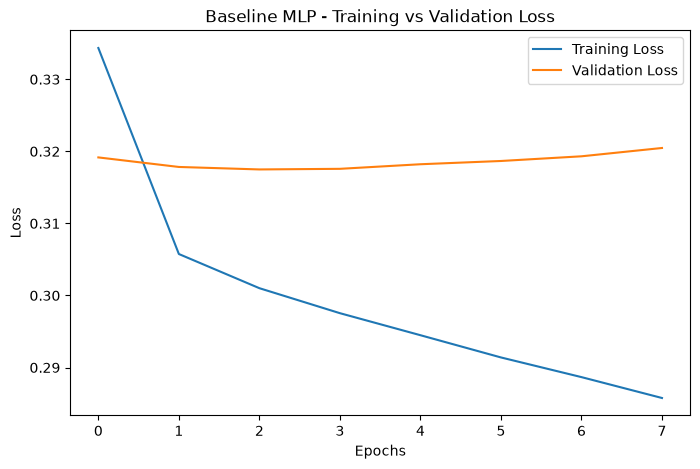

In [91]:
import matplotlib.pyplot as plt

history = histories["Baseline MLP"]

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Baseline MLP - Training vs Validation Loss")
plt.legend()

plt.savefig("baseline_loss_curve.png", bbox_inches="tight")
plt.show()

In [93]:
mlflow.log_artifact("baseline_loss_curve.png")

In [94]:
plt.savefig("baseline_loss_curve.png", bbox_inches="tight")

mlflow.log_artifact("baseline_loss_curve.png")

plt.show()

<Figure size 640x480 with 0 Axes>

In [95]:
import os

os.path.exists("baseline_loss_curve.png")

True

In [98]:
import os

os.path.abspath("baseline_loss_curve.png"), os.path.exists("baseline_loss_curve.png")

('c:\\Users\\tejas\\OneDrive\\week0\\ds-october-2026-week2\\week2\\baseline_loss_curve.png',
 True)

In [99]:
import mlflow

active_run = mlflow.active_run()

print(active_run.info.run_name)
print(active_run.info.run_id)

classy-skink-104
68a09366c8d84fb7ae53402c6e503740


In [97]:
mlflow.log_artifact("baseline_loss_curve.png")

In [104]:
import mlflow

run = mlflow.active_run()

if run is not None:
    print("Run ID:", run.info.run_id)
    print("Run name:", run.data.tags.get("mlflow.runName"))
else:
    print("No active run")

Run ID: 68a09366c8d84fb7ae53402c6e503740
Run name: classy-skink-104


In [106]:
import mlflow

client = mlflow.tracking.MlflowClient()

experiment = mlflow.get_experiment_by_name(
    "Adult Census - Week 2 Neural Networks"
)

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    max_results=50
)

for run in runs:
    print(
        "Run name:", run.info.run_name,
        "| Run ID:", run.info.run_id
    )

Run name: classy-skink-104 | Run ID: 68a09366c8d84fb7ae53402c6e503740
Run name: intelligent-eel-228 | Run ID: d591b0f14fe64d0cbdd5356ddf425ed5
Run name: SGD LR=0.001 | Run ID: fdd1b6b4a182439995421d3c4c0b86ba
Run name: SGD LR=0.01 | Run ID: c4aed856862e4e43b5c8d945262b2a0c
Run name: SGD LR=0.1 | Run ID: 682205eb5953465aaa4cec1cd4951c99
Run name: Adam LR=0.001 | Run ID: 20b3ba75bb3844068c2692131547bd0b
Run name: Adam LR=0.01 | Run ID: 5edfcab5832944e3afdbd38b73c14fdb
Run name: Adam LR=0.1 | Run ID: 690704bff140433ea2e98ffca704d34c
Run name: Regularised DNN | Run ID: d45d4f5b37a5427ebe914f1996ed6041
Run name: Deeper DNN | Run ID: 194c36446f9b43fab507a130805f0d73
Run name: Baseline MLP | Run ID: 9d53483c4a094135a4e2c888cc91cc7f
Run name: Baseline MLP | Run ID: b848a3e51a274da79c7402d0cb2355c0
Run name: Baseline MLP | Run ID: d6c9824c295f4aa4b71d820414a3b247
Run name: Baseline MLP | Run ID: 8d4066b651b84051b954fd12007a2fb1
Run name: Baseline MLP | Run ID: 83910ea2f6844a9ca0466d7f121d861b
R

In [109]:
import os

print(os.path.exists("baseline_loss_curve.png"))

True


In [112]:
import mlflow

client = mlflow.tracking.MlflowClient()

experiment = mlflow.get_experiment_by_name(
    "Adult Census - Week 2 Neural Networks"
)

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    max_results=100
)

for run in runs:
    if run.info.run_name == "Baseline MLP":
        print("Run ID:", run.info.run_id)
        print("Metrics:", run.data.metrics)
        print("-" * 40)

Run ID: 9d53483c4a094135a4e2c888cc91cc7f
Metrics: {'val_accuracy': 0.8509418509418509, 'val_precision': 0.7183235867446394, 'val_recall': 0.6267006802721088, 'val_f1': 0.6693914623069936, 'val_roc_auc': 0.9069293777381502, 'final_train_loss': 0.2857694625854492, 'final_val_loss': 0.3204658627510071}
----------------------------------------
Run ID: b848a3e51a274da79c7402d0cb2355c0
Metrics: {'val_accuracy': 0.8509418509418509, 'val_precision': 0.7183235867446394, 'val_recall': 0.6267006802721088, 'val_f1': 0.6693914623069936, 'val_roc_auc': 0.9069293777381502, 'final_train_loss': 0.2857694625854492, 'final_val_loss': 0.3204658627510071}
----------------------------------------
Run ID: d6c9824c295f4aa4b71d820414a3b247
Metrics: {'val_accuracy': 0.8509418509418509, 'val_precision': 0.7183235867446394, 'val_recall': 0.6267006802721088, 'val_f1': 0.6693914623069936, 'val_roc_auc': 0.9069293777381502, 'final_train_loss': 0.2857694625854492, 'final_val_loss': 0.3204658627510071}
---------------

In [113]:
for run in runs:
    if run.info.run_name == "Baseline MLP":
        print("Run ID:", run.info.run_id)
        print("Metrics:", run.data.metrics)
        print("Created:", run.info.start_time)
        print("-" * 50)

Run ID: 9d53483c4a094135a4e2c888cc91cc7f
Metrics: {'val_accuracy': 0.8509418509418509, 'val_precision': 0.7183235867446394, 'val_recall': 0.6267006802721088, 'val_f1': 0.6693914623069936, 'val_roc_auc': 0.9069293777381502, 'final_train_loss': 0.2857694625854492, 'final_val_loss': 0.3204658627510071}
Created: 1792413058570
--------------------------------------------------
Run ID: b848a3e51a274da79c7402d0cb2355c0
Metrics: {'val_accuracy': 0.8509418509418509, 'val_precision': 0.7183235867446394, 'val_recall': 0.6267006802721088, 'val_f1': 0.6693914623069936, 'val_roc_auc': 0.9069293777381502, 'final_train_loss': 0.2857694625854492, 'final_val_loss': 0.3204658627510071}
Created: 1792412384103
--------------------------------------------------
Run ID: d6c9824c295f4aa4b71d820414a3b247
Metrics: {'val_accuracy': 0.8509418509418509, 'val_precision': 0.7183235867446394, 'val_recall': 0.6267006802721088, 'val_f1': 0.6693914623069936, 'val_roc_auc': 0.9069293777381502, 'final_train_loss': 0.28576

In [114]:
import mlflow
from mlflow.tracking import MlflowClient
import os

client = MlflowClient()

run_id = "68a09366c8d84fb7ae53402c6e503740"

run = client.get_run(run_id)

print("Run name:", run.info.run_name)
print("Metrics:", run.data.metrics)

Run name: classy-skink-104
Metrics: {}


In [115]:
graph_path = "baseline_loss_curve.png"

print(os.path.exists(graph_path))

True


In [116]:
client.log_artifact(
    run_id,
    graph_path
)

In [107]:
print(mlflow.active_run())

<ActiveRun: >


In [102]:
import mlflow
import os

print(os.path.exists("baseline_loss_curve.png"))

True


In [96]:
with mlflow.start_run(run_id="YOUR_BASELINE_RUN_ID"):
    mlflow.log_artifact("baseline_loss_curve.png")

Exception: Run with UUID 68a09366c8d84fb7ae53402c6e503740 is already active. To start a new run, first end the current run with mlflow.end_run(). To start a nested run, call start_run with nested=True

In [81]:
import mlflow

mlflow.end_run()

In [83]:
import mlflow
import os

run_id = "d591b0f14fe64d0cbdd5356ddf425ed5"

with mlflow.start_run(run_id=run_id):
    for file in os.listdir("."):
        if file.endswith("_loss_curve.png"):
            mlflow.log_artifact(file)

In [85]:
import os

[file for file in os.listdir(".") if file.endswith("_loss_curve.png")]

['baseline_loss_curve.png',
 'baseline_mlp_loss_curve.png',
 'deeper_dnn_loss_curve.png',
 'regularised_dnn_loss_curve.png']

In [86]:

import mlflow
from mlflow.tracking import MlflowClient
import os

mlflow.set_tracking_uri(
    "sqlite:///C:/Users/tejas/OneDrive/week0/ds-october-2026-week2/week2/mlflow.db"
)

client = MlflowClient()

# Replace these two IDs with the actual Run IDs from MLflow
run_files = {
    "d591b0f14fe64d0cbdd5356ddf425ed5": "baseline_mlp_loss_curve.png",
    "PASTE_DEEPER_DNN_RUN_ID": "deeper_dnn_loss_curve.png",
    "PASTE_REGULARISED_DNN_RUN_ID": "regularised_dnn_loss_curve.png"
}

for run_id, file_path in run_files.items():
    if "PASTE_" in run_id:
        print(f"Add the actual Run ID for: {file_path}")
    elif os.path.exists(file_path):
        client.log_artifact(run_id, file_path)
        print(f"Uploaded: {file_path}")
    else:
        print(f"File not found: {file_path}")


Uploaded: baseline_mlp_loss_curve.png
Add the actual Run ID for: deeper_dnn_loss_curve.png
Add the actual Run ID for: regularised_dnn_loss_curve.png


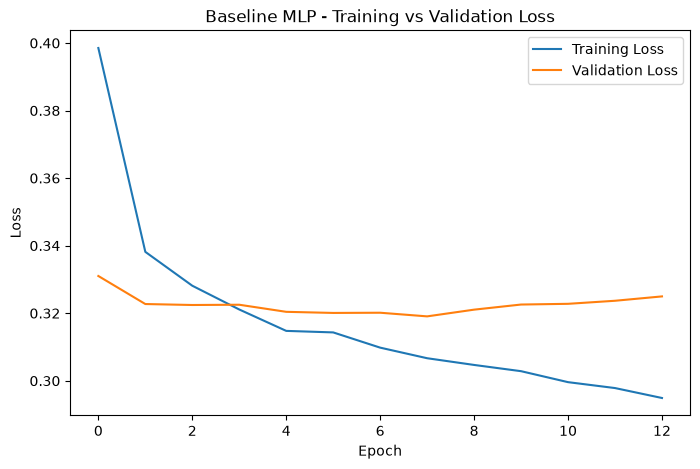

In [66]:
import matplotlib.pyplot as plt
import mlflow

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline MLP - Training vs Validation Loss")
plt.legend()

plt.savefig("baseline_loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [67]:
import mlflow

mlflow.log_artifact("baseline_loss_curve.png")

In [68]:
import mlflow

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("Current experiment:", mlflow.get_experiment_by_name(
    "Adult Census - Week 2 Neural Network"
))

MLflow tracking URI: sqlite:///C:/Users/tejas/OneDrive/week0/ds-october-2026-week2/week2/mlflow.db
Current experiment: None


In [71]:
import mlflow

print(mlflow.get_tracking_uri())
print(mlflow.search_experiments())


sqlite:///C:/Users/tejas/OneDrive/week0/ds-october-2026-week2/week2/mlflow.db
[<Experiment: artifact_location='file:c:/Users/tejas/OneDrive/week0/ds-october-2026-week2/week2/mlruns/1', creation_time=1792256915046, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792256915046, lifecycle_stage='active', name='Adult Census - Week 2 Neural Networks', tags={}, trace_location=None, workspace='default'>, <Experiment: artifact_location='file:c:/Users/tejas/OneDrive/week0/ds-october-2026-week2/week2/mlruns/0', creation_time=1792256915030, effective_trace_archival_retention=None, experiment_id='0', last_update_time=1792256915030, lifecycle_stage='active', name='Default', tags={}, trace_location=None, workspace='default'>]


In [72]:
import mlflow

mlflow.set_tracking_uri(
    "sqlite:///C:/Users/tejas/OneDrive/week0/ds-october-2026-week2/week2/mlflow.db"
)

In [74]:
import mlflow
import os

print("Current folder:", os.getcwd())
print("Tracking URI:", mlflow.get_tracking_uri())
print("Available experiments:")

for exp in mlflow.search_experiments():
    print(exp.name, exp.experiment_id)

Current folder: c:\Users\tejas\OneDrive\week0\ds-october-2026-week2\week2
Tracking URI: sqlite:///C:/Users/tejas/OneDrive/week0/ds-october-2026-week2/week2/mlflow.db
Available experiments:
Adult Census - Week 2 Neural Networks 1
Default 0


In [62]:
import mlflow

for exp in mlflow.search_experiments():
    print(exp.experiment_id, exp.name)

1 Adult Census - Week 2 Neural Networks
0 Default


In [75]:
import mlflow

mlflow.set_tracking_uri(
    "sqlite:///C:/Users/tejas/OneDrive/week0/ds-october-2026-week2/week2/mlflow.db"
)

for exp in mlflow.search_experiments():
    print("Experiment:", exp.name)

    runs = mlflow.search_runs(
        experiment_ids=[exp.experiment_id]
    )

    print("Number of runs:", len(runs))
    print(runs[["run_id", "status"]])

Experiment: Adult Census - Week 2 Neural Networks
Number of runs: 41
                              run_id    status
0   d591b0f14fe64d0cbdd5356ddf425ed5   RUNNING
1   fdd1b6b4a182439995421d3c4c0b86ba  FINISHED
2   c4aed856862e4e43b5c8d945262b2a0c  FINISHED
3   682205eb5953465aaa4cec1cd4951c99  FINISHED
4   20b3ba75bb3844068c2692131547bd0b  FINISHED
5   5edfcab5832944e3afdbd38b73c14fdb  FINISHED
6   690704bff140433ea2e98ffca704d34c  FINISHED
7   d45d4f5b37a5427ebe914f1996ed6041  FINISHED
8   194c36446f9b43fab507a130805f0d73  FINISHED
9   9d53483c4a094135a4e2c888cc91cc7f  FINISHED
10  b848a3e51a274da79c7402d0cb2355c0    FAILED
11  d6c9824c295f4aa4b71d820414a3b247    FAILED
12  8d4066b651b84051b954fd12007a2fb1    FAILED
13  83910ea2f6844a9ca0466d7f121d861b    FAILED
14  331617d0cb9f43ee9e49ec73ebe43c42  FINISHED
15  cc9f5ad16797429098ef6af46fddee68  FINISHED
16  f13b85b5e4494eb7843f37eb2c9143d0  FINISHED
17  5461f640d3824efb8489e4f2ba9b6d50  FINISHED
18  a866215b9ecf406ab9ed487e2fe048ea  

## 14. Final test evaluation — run after choosing the model

The test set is used only now, after model selection. Do not use these test results to keep tuning or choosing between models. If you change the model based on these results, the test set is no longer an untouched final test.

Final selected model: Baseline MLP
Test accuracy: 0.8536335721596725
Test precision: 0.7244401168451802
Test recall: 0.6326530612244898
Test F1: 0.675442578302315
Test ROC-AUC: 0.9061099770185777
              precision    recall  f1-score   support

Income <=50K       0.89      0.92      0.91      3709
 Income >50K       0.72      0.63      0.68      1176

    accuracy                           0.85      4885
   macro avg       0.81      0.78      0.79      4885
weighted avg       0.85      0.85      0.85      4885



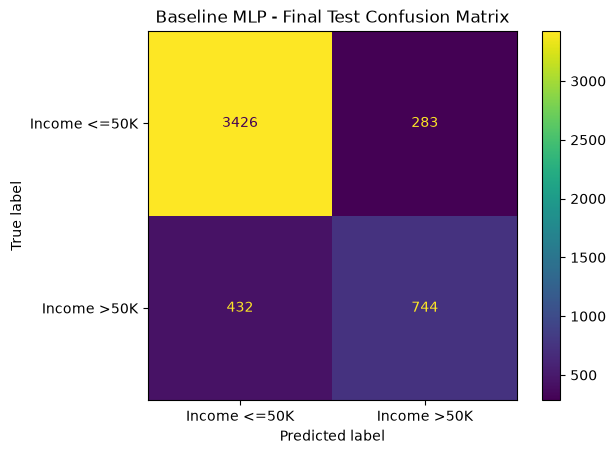

In [60]:
test_probabilities = best_model.predict(X_test, verbose=0).ravel()
test_predictions = (test_probabilities >= 0.5).astype(int)

print("Final selected model:", best_name)
print("Test accuracy:", accuracy_score(y_test, test_predictions))
print("Test precision:", precision_score(y_test, test_predictions, zero_division=0))
print("Test recall:", recall_score(y_test, test_predictions, zero_division=0))
print("Test F1:", f1_score(y_test, test_predictions, zero_division=0))
print("Test ROC-AUC:", roc_auc_score(y_test, test_probabilities))

print(classification_report(
    y_test,
    test_predictions,
    target_names=["Income <=50K", "Income >50K"],
    zero_division=0
))

cm = confusion_matrix(y_test, test_predictions)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Income <=50K", "Income >50K"]
).plot()
plt.title(f"{best_name} - Final Test Confusion Matrix")
plt.show()

## 15. Save the selected model and preprocessing pipeline

The neural network consumes preprocessed numeric arrays, so save both the Keras model and the fitted scikit-learn preprocessor. Use the same preprocessor for future input data.

In [54]:
best_model.save("adult_census_best_model.keras")

import joblib
joblib.dump(preprocessor, "adult_census_preprocessor.joblib")

print("Saved adult_census_best_model.keras")
print("Saved adult_census_preprocessor.joblib")

Saved adult_census_best_model.keras
Saved adult_census_preprocessor.joblib


## results

- **Baseline MLP:** the benchmark with two ReLU hidden layers and Adam.
- **Deeper DNN:** compare its training and validation curves. A widening train/validation gap can indicate overfitting; poor results on both may indicate underfitting, optimisation issues, or a setup problem.
- **Regularised DNN:** dropout, batch normalisation, and early stopping are intended to improve generalisation; they do not guarantee a better score.
- **Optimizer / learning-rate runs:** all use the same 64-32-1 MLP architecture. Compare validation metrics, not test metrics, while experimenting.
- **Final selection:** this notebook ranks candidates by validation F1 score. If the trainer requires a different selection objective, change that criterion before running the final test evaluation.
- **Class definitions:** `0` means income `<=50K`; `1` means income `>50K`.
